In [20]:
# Importing the python libraries
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score, r2_score, roc_auc_score
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV

In [21]:
Modelling_Data = pd.read_csv(r'../dataset/artifacts/Engineered_Data.csv')
Modelling_Data.head()

,timestamp,home_country,source_currency,dest_currency,channel,amount_src,amount_usd,fee,new_device,ip_country,...,corridor_risk,is_fraud,hour,late_night_hours,amount_high,high_ip_risk,low_device_trust,new_account,very_new_account,velocity_spike
0,2022-10-03 18:40:59.468549+00:00,us,USD,CAD,atm,278.19,278.19,3.48,False,us,...,0.0,0,18,0,0,0,0,0,0,0
1,2022-10-03 20:39:38.468549+00:00,ca,CAD,MXN,web,208.51,154.29,3.48,True,ca,...,0.0,0,20,0,0,0,1,0,0,0
2,2022-10-03 23:02:43.468549+00:00,us,USD,CNY,mobile,160.33,160.33,3.48,False,us,...,0.0,0,23,0,0,0,0,0,0,0
3,2022-10-04 01:08:53.468549+00:00,us,USD,EUR,mobile,59.41,59.41,3.48,False,us,...,0.0,0,1,0,0,0,0,0,0,0
4,2022-10-04 09:35:03.468549+00:00,us,USD,INR,mobile,200.96,200.96,3.48,False,us,...,0.0,0,9,0,0,0,0,0,0,0


In [22]:
Modelling_Data['timestamp'] = pd.to_datetime(Modelling_Data['timestamp'])

In [23]:
categorical_features = Modelling_Data.select_dtypes(include=['object', 'bool']).columns
categorical_features

C:\Users\pc\AppData\Local\Temp\ipykernel_13968\1983673620.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = Modelling_Data.select_dtypes(include=['object', 'bool']).columns


Index(['home_country', 'source_currency', 'dest_currency', 'channel',
       'new_device', 'ip_country', 'location_mismatch', 'kyc_tier'],
      dtype='str')

NOTE we drop Is_fraud bcos is a target variable you cannot train on target variable

In [24]:
numerical_features = Modelling_Data.select_dtypes(include=['int', 'float']).columns.drop('is_fraud') 
numerical_features

Index(['amount_src', 'amount_usd', 'fee', 'ip_risk_score', 'account_age_days',
       'device_trust_score', 'risk_score_internal', 'txn_velocity_1h',
       'txn_velocity_24h', 'corridor_risk', 'hour', 'late_night_hours',
       'amount_high', 'high_ip_risk', 'low_device_trust', 'new_account',
       'very_new_account', 'velocity_spike'],
      dtype='str')

In [25]:
all_features = list(categorical_features) + list(numerical_features)
print(all_features)

['home_country', 'source_currency', 'dest_currency', 'channel', 'new_device', 'ip_country', 'location_mismatch', 'kyc_tier', 'amount_src', 'amount_usd', 'fee', 'ip_risk_score', 'account_age_days', 'device_trust_score', 'risk_score_internal', 'txn_velocity_1h', 'txn_velocity_24h', 'corridor_risk', 'hour', 'late_night_hours', 'amount_high', 'high_ip_risk', 'low_device_trust', 'new_account', 'very_new_account', 'velocity_spike']


In [26]:
len(all_features)

26

Train_test_split
The data is split into: 80% of data used to train the model and 20% is reserved to test its performance on unseen data.
It is strongly recommended to sort the dataset chronologically before doing the train-test split.Since your dataset  has a timestamp column the order of events matters. This will prevent data leakage , help predict future transactionsince model will trained on past transactions hence mimicing the eal scenario.

Feature like: txn_velocity_1h, txn_velocity_24h, new_device, account_age_days, new_account depend on historical orderdata is not ordered bt time these features can become incorrect

In [27]:
# sort by timestamp
Modelling_Data = Modelling_Data.sort_values(by='timestamp')

# 80/20 train_test split
split_index = int(len(Modelling_Data) * 0.8) # This determines where the dataset should be split
train_Modelling_Data = Modelling_Data.iloc[:split_index] # Training on feature  transactions
test_Modelling_Data = Modelling_Data.iloc[split_index:]# testing on past transactions

# preparing x and Y
X_train = train_Modelling_Data[all_features]
y_train = test_Modelling_Data['is_fraud']
X_test = test_Modelling_Data[all_features]
y_test = test_Modelling_Data['is_fraud']

print(f"\nX_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")


X_train: (8643, 26), y_train: (2161,)
X_test: (2161, 26), y_test: (2161,)


In [28]:
# Building a preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_features)
    ]
)

Training Logistic Regression with a Balanced Class Weight

In [29]:
# 1. Correct the target assignment from the previous cell's split error
y_train = train_Modelling_Data['is_fraud']
y_test = test_Modelling_Data['is_fraud']

# 2. Re-build preprocessor to impute missing values (NaNs)
imputed_preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_features),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
        ]), categorical_features)
    ]
)

# create Logistic Regression Model
lr_model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

# Build the complete pipeline
pipeline = Pipeline(
    steps=[
        ('preprocessor', imputed_preprocessor),
        ('classifier', lr_model)
    ]
)

# Train the pipeline
pipeline.fit(X_train, y_train)

# make predictions
y_pred_lr = pipeline.predict(X_test)
y_proba_lr = pipeline.predict_proba(X_test)[:, 1]

# Evaluation 
print("Logistic Regression Results:")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr, target_names=['Genuine', 'Fraud']))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))
print(f"\nROC_AUC score: {roc_auc_score(y_test, y_pred_lr):.4f}")

Logistic Regression Results:

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.99      0.96      0.98      1853
       Fraud       0.80      0.95      0.87       308

    accuracy                           0.96      2161
   macro avg       0.90      0.95      0.92      2161
weighted avg       0.96      0.96      0.96      2161


Confusion Matrix:
[[1782   71]
 [  16  292]]

ROC_AUC score: 0.9549


Confusion Matrix For Linear Regression

<Figure size 800x600 with 0 Axes>

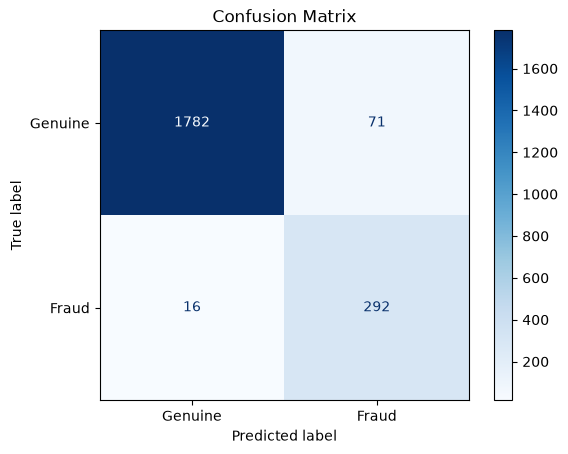

In [30]:
from sklearn.metrics import ConfusionMatrixDisplay

# Correctly generate the plot directly from predictions
plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_pred_lr,
    display_labels=['Genuine', 'Fraud'],
    cmap='Blues'
)
plt.title("Confusion Matrix")
plt.show()

Training Random Forest With Balanced Class Wieght

In [31]:
from sklearn.ensemble import RandomForestClassifier

# create Random Forest Model
rf_model = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_estimators=100,
    max_depth=10,
    n_jobs=-1
)

# Build the complete pipeline with both the imputer preprocessor and the classifier
pipeline_rf = Pipeline(
    steps=[
        ('preprocessor', imputed_preprocessor),
        ('classifier', rf_model)
    ]
)

# Train the pipeline
pipeline_rf.fit(X_train, y_train)

# make prediction
y_pred_rf = pipeline_rf.predict(X_test)
y_proba_rf = pipeline_rf.predict_proba(X_test)[:, 1]

# Evaluation
print("Random Forest Results:")
print("\nclassification Report:")
print(classification_report(y_test, y_pred_rf, target_names=['Genuine', 'Fraud']))
print("\nconfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
print(f"\nROC_AUC score: {roc_auc_score(y_test, y_proba_rf):.4f}")

Random Forest Results:

classification Report:
              precision    recall  f1-score   support

     Genuine       0.99      0.99      0.99      1853
       Fraud       0.96      0.92      0.94       308

    accuracy                           0.98      2161
   macro avg       0.97      0.96      0.96      2161
weighted avg       0.98      0.98      0.98      2161


confusion Matrix:
[[1840   13]
 [  24  284]]

ROC_AUC score: 0.9768


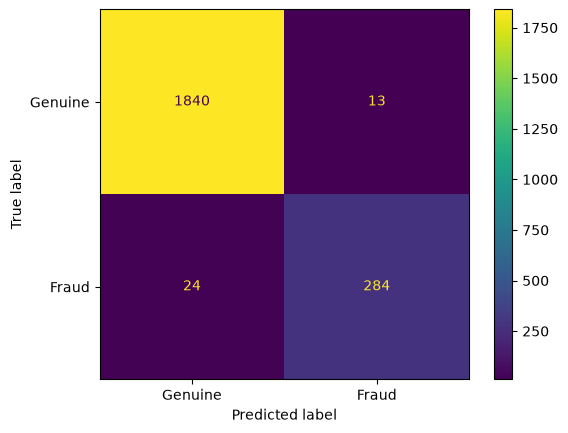

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

cm = ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_rf), display_labels=['Genuine', 'Fraud'])
plt.Figure(figsize=(8, 6))
cm.plot()

In [33]:
from xgboost import XGBClassifier

# calculate scale pos weight for imbalance in xgboost classifier
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# create XGBoost model
xgb_model = XGBClassifier(
    random_state=42,
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight,
    eval_metrics='logloss' 
)

# Build the complete pipeline
pipeline_xgb = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', xgb_model)
    ]
)

# Train the pipeline (using raw X_train, not processed)
pipeline_xgb.fit(X_train, y_train)

# make predictions

y_pred_xgb = pipeline_xgb.predict(X_test)
y_proba_xgb = pipeline_xgb.predict_proba(X_test)[:, 1]

# Evaluation
print("XGBBoost Results:")
print("\nclassification Report:")
print(classification_report(y_test, y_pred_xgb, target_names=['Genuine', 'Fraud']))
print ("\nconfusion matrix:")
print(confusion_matrix(y_test, y_pred_xgb))
print(f"\nROC_AUC score: {roc_auc_score(y_test, y_proba_xgb):.4f}")

c:\Users\pc\Downloads\Fraudulent_Transaction_Detection_Using_Machine_Learning\finlora_env\Lib\site-packages\xgboost\training.py:200: UserWarning: [12:53:17] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "eval_metrics" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBBoost Results:

classification Report:
              precision    recall  f1-score   support

     Genuine       0.99      0.99      0.99      1853
       Fraud       0.93      0.92      0.92       308

    accuracy                           0.98      2161
   macro avg       0.96      0.95      0.96      2161
weighted avg       0.98      0.98      0.98      2161


confusion matrix:
[[1831   22]
 [  25  283]]

ROC_AUC score: 0.9712


Confusion matrix for xgboost

<Figure size 800x600 with 0 Axes>

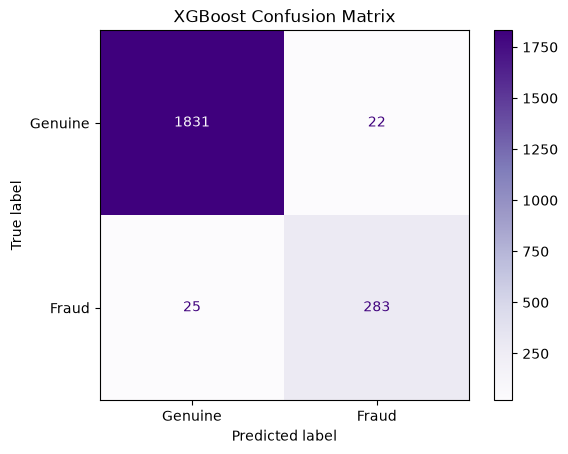

In [34]:
from sklearn.metrics import ConfusionMatrixDisplay

# Correctly generate the plot directly from predictions
plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_pred_xgb,
    display_labels=['Genuine', 'Fraud'],
    cmap='Purples'
)
plt.title("XGBoost Confusion Matrix")
plt.show()

SHARP ANALYSIS
Shap is a technique used to explain machine learning prediction especially  models like tree ensemble in a awy that shows how each feature contribute  to a decision.
Shap answers this question: Why did the model say this transaction is fraud ?
Its does this by assigning each feature a contribution value ( positive or negative) to the prediction. Shap is uded to interpret model predictions by quantifying the contribution of each feature to fraud risk. This enables transparency in decision making helped identify key fraud drivers such as transaction velocity and Ip risk score and provide actionable insight for fraud analysis and business stakeholders. 
Shap is based on Game Theory specifically sharpley values. Its fairly distributes the "credits of a prediction across features 

In [35]:
%pip install shap xgboost


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
import shap
import xgboost

import importlib.metadata

print("SHAP version:", importlib.metadata.version("shap"))
print("XGBoost version:", xgboost.__version__)

SHAP version: 0.54.1
XGBoost version: 3.4.1


In [37]:
import shap
import pandas as pd
import matplotlib.pyplot as plt

# Get the preprocessor from pipeline and transform raw X_test
X_test_processed = pipeline_xgb.named_steps['preprocessor'].transform(X_test)

# Get the XGBoost model from pipeline
xgb_model = pipeline_xgb.named_steps['classifier']

# Get booster and calculate SHAP value

booster = xgb_model.get_booster()
explainer = shap.TreeExplainer(booster)
shap_value_gb = explainer.shap_values(X_test_processed)

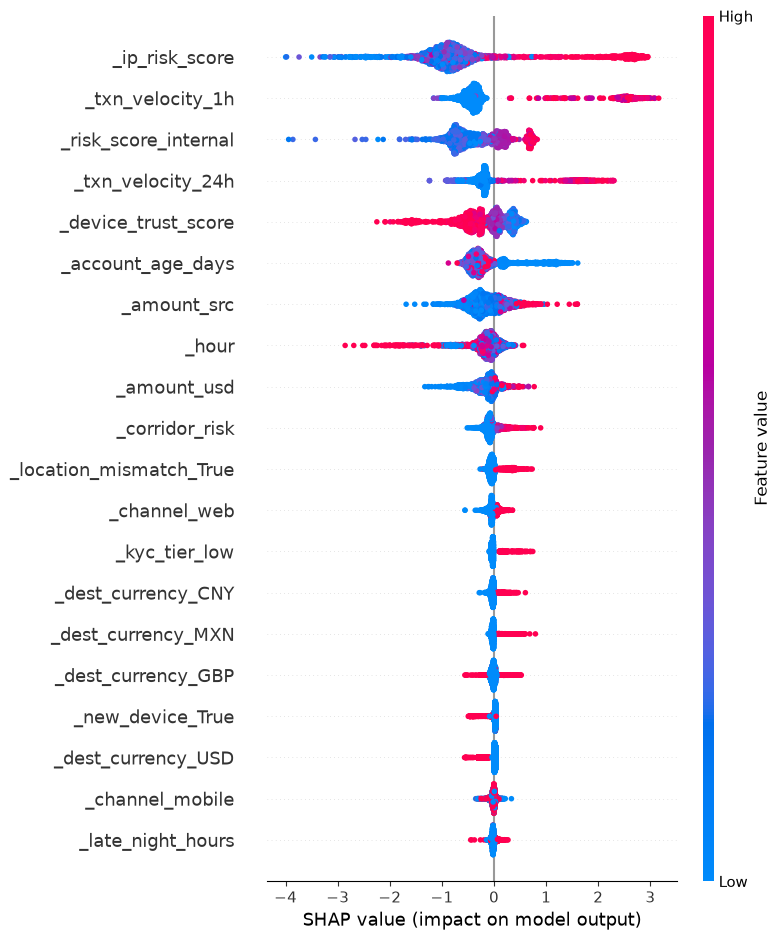

In [38]:
# creating a clean feature name fro the shap plot
feature_names = pipeline_xgb.named_steps['preprocessor'].get_feature_names_out()
clean_names = [name.replace("num_", "").replace("cat_", "") for name in feature_names]
X_test_processed_df = pd.DataFrame(
    X_test_processed,
    columns=clean_names
)

# Beeswarm plot
shap.summary_plot(shap_value_gb, X_test_processed_df)
plt.show()

This a shap beeswarm plot, and it shows which features matters most and how they influence fraud predictions. The Y-axis shows the features (ranked by importance) while the X-axis shows the SHAP value (impact on prediction). The Blue color represents Low feature value while the red color represnt High feature value.

The Left part of the plot(Negative SHAP value) pushes prediction toward Genuine while the Right part (positive SHAP value) pushes prediction towards Fraud.

The SHAP beeswarm plot highlights that transaction velocity spikes, location mismatch, internal risk score, and ip risk scores are the most influential drivers of fraud predictions. High values of these features consistently push predictions toward fraud , while low values indicate genuine behaviour. The model captures a combination of behavioural anomalies identity inconsistency and account risk factors aligning closely with real-world fraud detection patterns

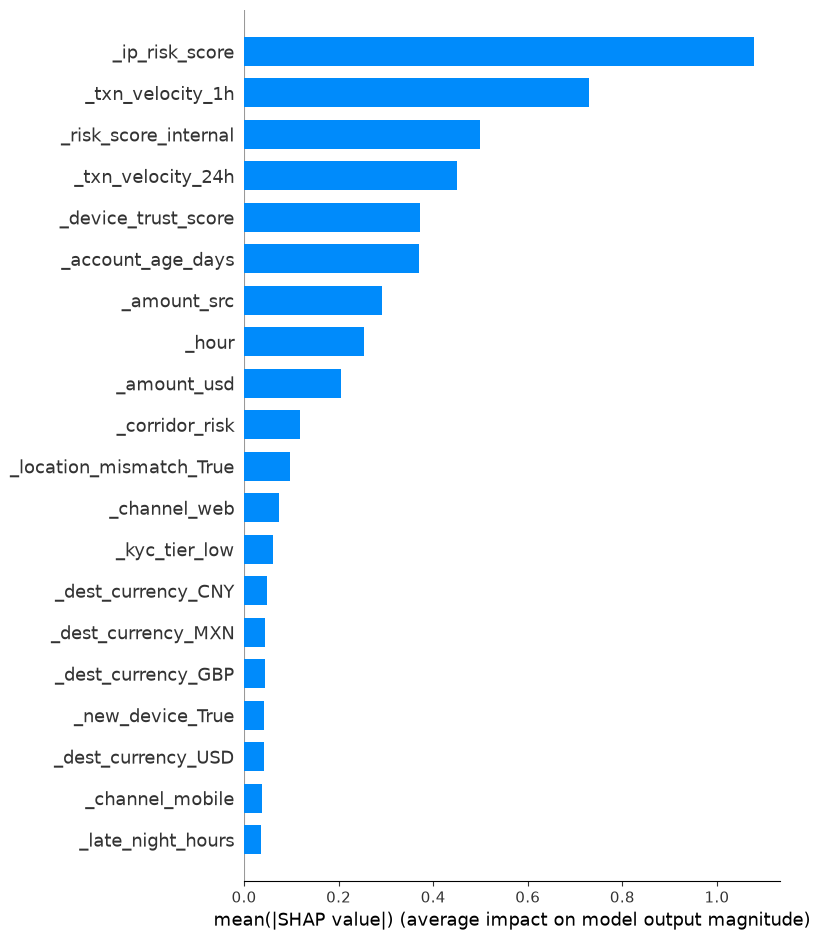

In [39]:
# summary bar plot
shap.summary_plot(shap_value_gb, X_test_processed_df, plot_type="bar")

MODEL REGISTERING

In [41]:
import dagshub
import mlflow
import mlflow.sklearn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# Intialize DagsHub
import dagshub
dagshub.init(repo_owner='victoroluikpe',
             repo_name='Fraudulent_Transaction_Detection_For_Finlora_Company',
             mlflow=True
            
)

Accessing as victoroluikpe

Repository Fraudulent_Transaction_Detection_For_Finlora_Company doesn't exist, creating it under current user.

Initialized MLflow to track repo "victoroluikpe/Fraudulent_Transaction_Detection_For_Finlora_Company"

Repository victoroluikpe/Fraudulent_Transaction_Detection_For_Finlora_Company initialized!

In [ ]:
# start Mlflow run and register model
with mlflow.start_run() as run:
    # Log model parameters
    mlflow.log_params(xgb_model.get_params())

    # make predictions using the pipeline
    y_pred = pipeline_xgb.predict(X_test)
    y_pred_proba = pipeline_xgb.predict_proba(X_test)[:, 1]

    # Log metrics
    mlflow.log_metrics({
        'accuracy': accuracy_score(y_test, y_pred),
        'precision': precision_score(y_test, y_pred),
        'recall': recall_score(y_test, y_pred),
        'f1_score': f1_score(y_test, y_pred),
        'auc_roc': roc_auc_score(y_test, y_pred_proba)
    })

    # Log the entire pipeline (preprocessor + model) with cloudpickle serialization
    mlflow.sklearn.log_model(
        pipeline_xgb,
        "xgboost_fraud_detection_pipeline",
        registered_model_name="Fraud_Detection_XGBoost_pipeline",
        serialization_format='cloudpickle'
    )

    print(f"Model registered sucessfully!")
    print(f"Run ID: {run.info._run_id}")